In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
import pandas as pd

# Updated path to point to the available sample dataset
df = pd.read_csv("/content/sample_data/california_housing_train.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (17000, 9)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


In [7]:
# Using features and target from the loaded California Housing dataset
features = ["total_rooms", "total_bedrooms", "median_income"]
target = "median_house_value"

print("Missing values:")
print(df[features + [target]].isnull().sum())

# Drop any rows with missing values in these columns
df = df.dropna(subset=features + [target]).copy()

print("Dataset shape after cleaning:", df.shape)

Missing values:
total_rooms           0
total_bedrooms        0
median_income         0
median_house_value    0
dtype: int64
Dataset shape after cleaning: (17000, 9)


In [8]:
X = df[features]
y = df[target]

print("Input data:")
display(X.head())

print("Target prices:")
display(y.head())

Input data:


,total_rooms,total_bedrooms,median_income
0,5612.0,1283.0,1.4936
1,7650.0,1901.0,1.8200
2,720.0,174.0,1.6509
3,1501.0,337.0,3.1917
4,1454.0,326.0,1.9250


Target prices:


,median_house_value
0,66900.0
1,80100.0
2,85700.0
3,73400.0
4,65500.0


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 13600
Testing samples: 3400


In [10]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [11]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": y_pred
})

display(results.head(10).round(2))

,Actual Price,Predicted Price
10941,142700.0,186990.41
5250,500001.0,392191.98
10292,61800.0,140134.33
2266,162800.0,192461.11
6398,90600.0,100608.05
4064,232100.0,278163.79
8018,147800.0,144937.58
3934,133300.0,136023.37
16287,438500.0,310331.85
8875,187700.0,262815.52


In [12]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"MAE: ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R2 Score: {r2:.4f}")

MAE: $59,395.21
RMSE: $80,403.02
R2 Score: 0.5308


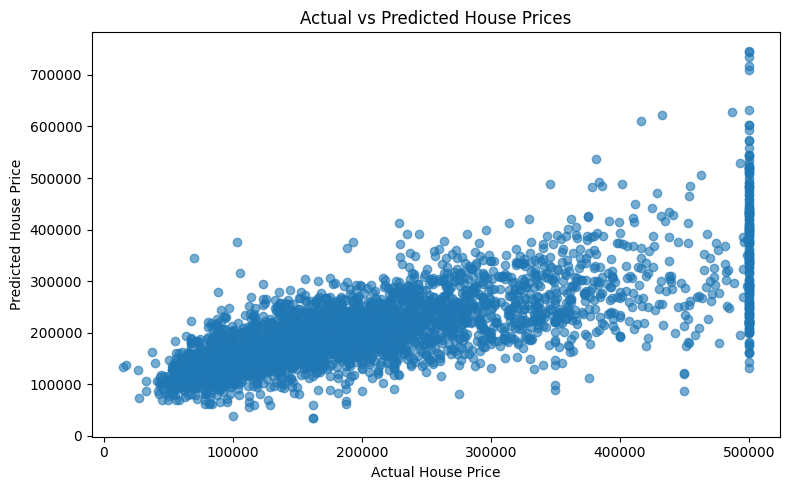

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")

plt.tight_layout()
plt.show()

In [15]:
# Define a new house using the features the model was actually trained on
new_house = pd.DataFrame({
    "total_rooms": [6.0],
    "total_bedrooms": [2.0],
    "median_income": [4.5]
})

predicted_price = model.predict(new_house)

print(f"Predicted House Price: ${predicted_price[0]:,.2f}")

Predicted House Price: $230,983.59
